Метод главных компонент

Берем многомерные данные, будем выдавать вектора для всех осей (главные компоненты), изменять их с помощью матричных операций, так чтобы они были ортогональны (пытаемся сохранить по умолчанию 90% дисперсии)

In [6]:
import numpy as np

# Делаем сами данный метод
x = np.arange(1, 11)
y = 2 * x + np.random.randn(10) * 2
X = np.vstack((x, y))

Xcentered = (X[0] - x.mean(), X[1] - y.mean())
m = (x.mean(), y.mean())

print('Mean vector: ', m)
covmat = np.cov(Xcentered)
print('Covarience matrix: \n', covmat, '\n')
print('Varience of X: ', covmat[0, 0])
print('Varience of Y: ', covmat[1, 1])
print('Varience of X and Y: ', covmat[0, 1])

num, vecs = np.linalg.eig(covmat)

ind = np.argsort(-num) #так как нампай сортирует по возрастанию, а надо наоборот
vecs = vecs[:, ind]
num = num[ind]
print('Eigen numbers ', num)
print('Eigen vectors\n', vecs)
v = vecs[:, 0] # главная компонента
Xproj = np.dot(v, Xcentered)

n = 9
Xrestored = Xproj[n] * v + m
print('Restored ', Xrestored)
print('Original: ', X[:, n])

Mean vector:  (np.float64(5.5), np.float64(11.124774179522513))
Covarience matrix: 
 [[ 9.16666667 17.71250222]
 [17.71250222 37.81772912]] 

Varience of X:  9.166666666666666
Varience of Y:  37.817729117335944
Varience of X and Y:  17.71250222193211
Eigen numbers  [46.27275056  0.71164522]
Eigen vectors
 [[-0.43078466 -0.90245475]
 [-0.90245475  0.43078466]]
Restored  [ 9.49236352 19.48841325]
Original:  [10.         19.24609416]


In [7]:
from sklearn.decomposition import PCA


pca = PCA(n_components=1)
XPCAreduced = pca.fit_transform(np.transpose(X))

print('Our reduced X: \n', Xproj)
print('Sklearn reduced X: \n', XPCAreduced)

print('Mean vector\n', pca.mean_, m)
print('Projection: ', pca.components_, v)
print('Explained variance ratio: ', pca.explained_variance_ratio_)

Our reduced X: 
 [ 9.82748668  7.39847007  4.17812143  6.12664805  1.91542495 -4.29585062
 -3.62986237 -3.49091031 -8.76187312 -9.26765477]
Sklearn reduced X: 
 [[-9.82748668]
 [-7.39847007]
 [-4.17812143]
 [-6.12664805]
 [-1.91542495]
 [ 4.29585062]
 [ 3.62986237]
 [ 3.49091031]
 [ 8.76187312]
 [ 9.26765477]]
Mean vector
 [ 5.5        11.12477418] (np.float64(5.5), np.float64(11.124774179522513))
Projection:  [[0.43078466 0.90245475]] [-0.43078466 -0.90245475]
Explained variance ratio:  [0.98485358]


Посмотрим на примере классификации

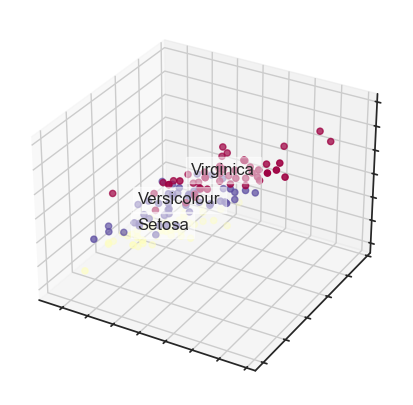

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style='white')
from sklearn import datasets
from mpl_toolkits import mplot3d


iris = datasets.load_iris()
X = iris.data
y = iris.target

fig = plt.figure(1, figsize=(6, 5))
ax = plt.axes(projection='3d')

for name, label in [('Setosa', 0), ('Versicolour', 1), ('Virginica', 2)]:
    ax.text3D(X[y == label, 0].mean(),
              X[y == label, 1].mean(),
              X[y == label, 2].mean(),
              name,
              horizontalalignment='center',
              bbox=dict(alpha=.5, edgecolor='w', facecolor='w'))

y_clr = np.choose(y, [1, 2, 0]).astype('float64')
ax.scatter(xs=X[:, 0], ys=X[:, 1], zs=X[:, 2], c=y_clr, cmap=plt.cm.Spectral)

ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])
plt.show()

Классифицируем при помощи деревьев решений

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.3, stratify=y, random_state=42)
clf = DecisionTreeClassifier(max_depth=2, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict_proba(X_test)
print('Accuracy score: {:.5f}'.format(accuracy_score(y_test, y_pred.argmax(axis=1))))

Accuracy score: 0.88889


In [15]:
pca = PCA(n_components=2)
X_centered = X - X.mean(axis=0)
pca.fit(X_centered)
X_pca = pca.transform(X_centered)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=.3, stratify=y, random_state=42)
clf = DecisionTreeClassifier(max_depth=2, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict_proba(X_test)
print('Accuracy score: {:.5f}'.format(accuracy_score(y_test, y_pred.argmax(axis=1))))

Accuracy score: 0.91111


In [17]:
for i, component in enumerate(pca.components_):
    print('{} component {}% of initial varience'.format(i+1, round(100 * pca.explained_variance_ratio_[i])))
    print(' + '.join('%.3f x %s' % (value, name) for value, name in zip(component, iris.feature_names)))

1 component 92% of initial varience
0.361 x sepal length (cm) + -0.085 x sepal width (cm) + 0.857 x petal length (cm) + 0.358 x petal width (cm)
2 component 5% of initial varience
0.657 x sepal length (cm) + 0.730 x sepal width (cm) + -0.173 x petal length (cm) + -0.075 x petal width (cm)


Projecting 64-dimensional data to 2D


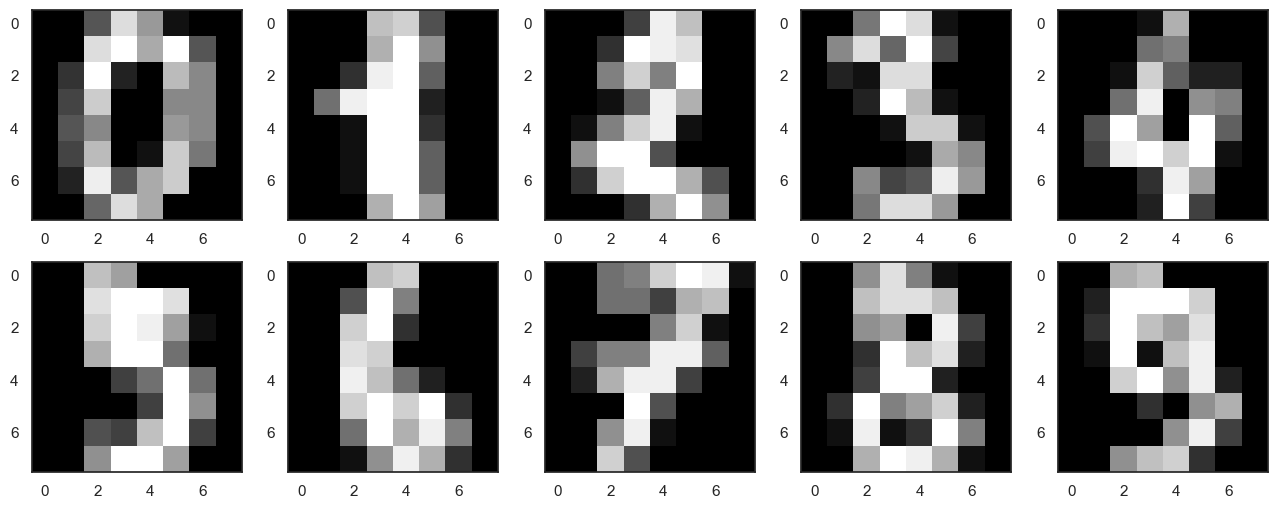

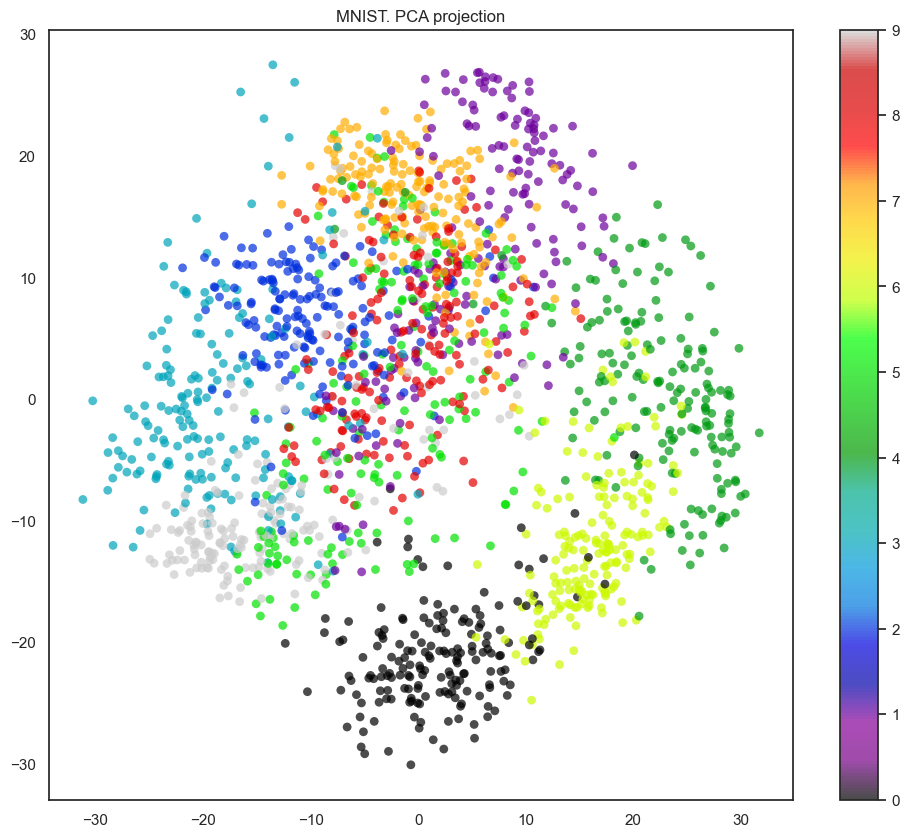

In [20]:
digits = datasets.load_digits()
X = digits.data
y = digits.target

plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i, :].reshape([8, 8]), cmap='grey')

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

print('Projecting %d-dimensional data to 2D' % X.shape[1])

plt.figure(figsize=(12, 10))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1],
            c=y, edgecolors='none',
            alpha=.7, s=40, cmap=plt.colormaps.get_cmap('nipy_spectral'))

plt.colorbar()
plt.title('MNIST. PCA projection')
plt.show()


90% varience at component № 21


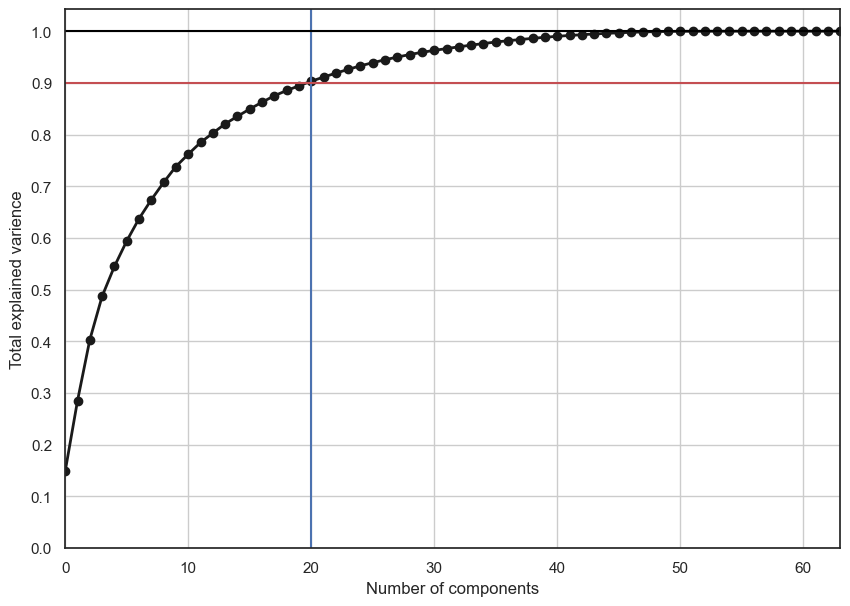

In [26]:
pca = PCA().fit(X)
plt.figure(figsize=(10, 7))
# процент объяснённой дисперсии
evr = np.cumsum(pca.explained_variance_ratio_)
plt.plot(evr, color='k', lw=2, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Total explained varience')
plt.xlim(0, 63)
plt.yticks(np.arange(0, 1.1, .1))


cmp = np.where(evr > .9)[0][0]
print('90% varience at component №', cmp + 1)

plt.grid(True)
plt.axvline(cmp, c='b')
plt.axhline(.9, c='r')
plt.axhline(1, c='black')

Метод t-SNE

PCA находит только линейные зависимости, а t-SNЕ B не линейные, более сложный.

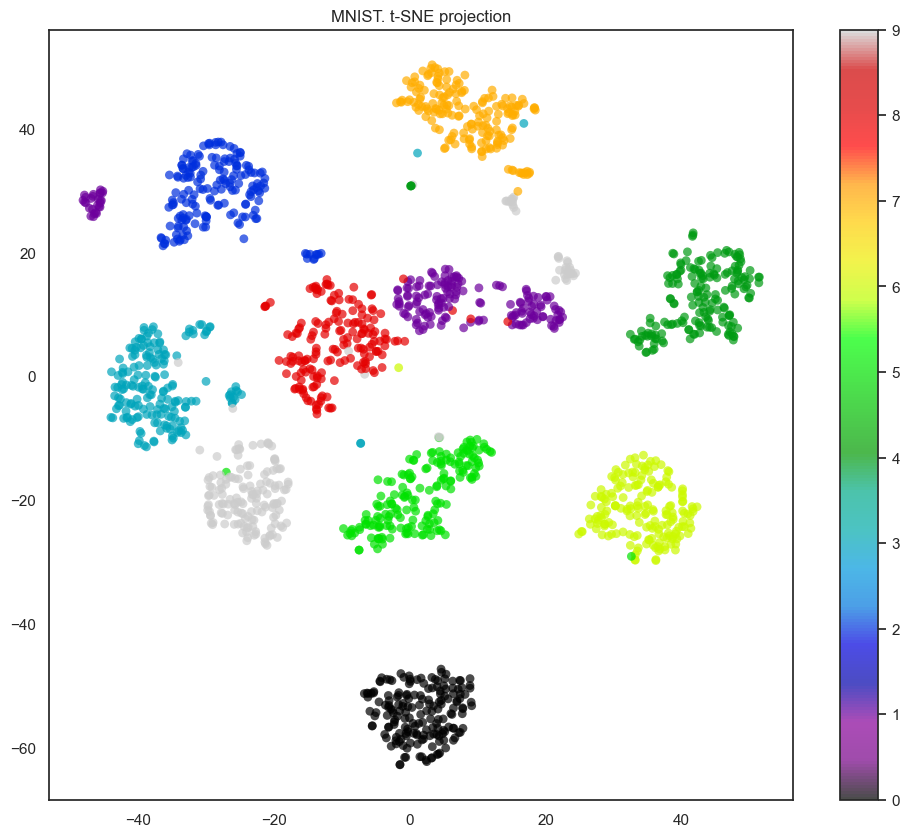

In [27]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, random_state=17)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(12, 10))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y,
            edgecolors='none', s=40, alpha=.7,
            cmap=plt.colormaps.get_cmap('nipy_spectral'))

plt.colorbar()
plt.title('MNIST. t-SNE projection')
plt.show()

Анализ независимых компонентов

нет требования делать компоненты ортогональными (пример, а что мешает сделать другие условия в PCA)

![Снимок экрана 2026-02-02 201507.png](<attachment:Снимок экрана 2026-02-02 201507.png>)
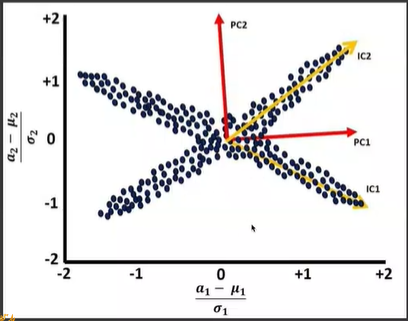

В основном хуже работает метода главных компонент, но лучше работает с сигналами

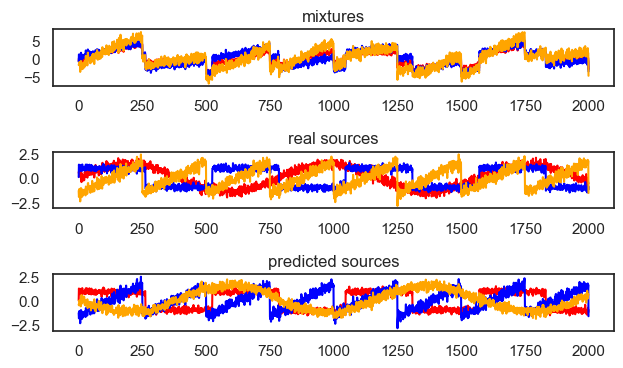

In [29]:
from scipy import signal
from sklearn.decomposition import FastICA


np.random.seed(0)
n_samples = 2000
# Длина каждого сигнала
time = np.linspace(0, 8, n_samples)
s1 = np.sin(2 * time)
s2 = np.sign(np.sin(3 * time))
s3 = signal.sawtooth(2 * np.pi * time)
S = np.c_[s1, s2, s3]
S += .2 * np.random.normal(size=S.shape)
S /= S.std(axis=0) # мат ожидание по оси 0
A = np.array([[1, 1, 1], [.5, 2, 1], [1.5, 1, 2]]) #матрица преобразования / смеси сигналов
X = np.dot(S, A.T)


ica = FastICA(n_components=3)
S_ = ica.fit_transform(X)

fig = plt.figure()

models = [X, S, S_]
names = ['mixtures', 'real sources', 'predicted sources']
colors = ['red', 'blue', 'orange']
for i, (name, model) in enumerate(zip(names, models)):
    plt.subplot(4, 1, i + 1)
    plt.title(name)
    for sig, color in zip(model.T, colors):
        plt.plot(sig, color=color)

fig.tight_layout()
plt.show()
